# Micrograd

##### Micrograd is an automatic gradient(Autograd) engine that impliments backpropagation.
##### Backpropagation is an algorithm that efficiently evaluate the gradient of a loss function with respect to the weights of a neural network. 
##### By doing this we can iteratively reduce the loss function and improve the accuracy.

### Understanding Derivative 

In [1]:
import math 
import numpy as np 
import matplotlib.pyplot as plt 
%matplotlib inline 

In [2]:
# define the scalar valued function
def f(x):
    return 3*x**2 - 4*x +5
    

In [3]:
f(3.0)

20.0

In [4]:
# Create a set of scalar values to evaluate the function from -5 to 5 with a step size of 0.25. 5 is not included in the range.
xs = np.arange(-5,5,0.25)
xs

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

In [5]:
# Call the function on the numpy array of scalar values to get the corresponding function values.
ys = f(xs)
ys 

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

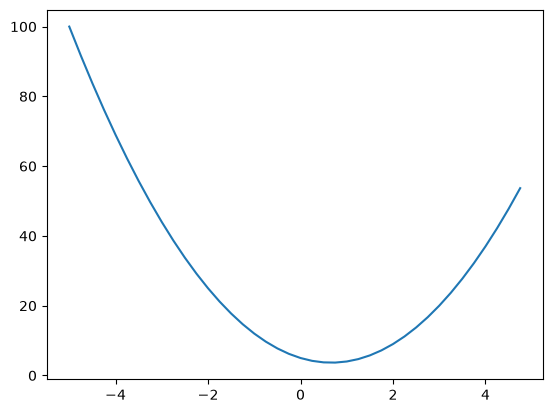

In [6]:
# Plot the results using matplotlib
plt.plot(xs,ys)

##### The next step is to check what is the derivative of the function at different points of x 

##### The formula used for reference is 
https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/karpathy1_ref_img1.png

In [7]:
h = 0.001
x = 3.0
# This shows if we slightly change the value of x in a positive direction how is the function going to respond 
f(x+h)


20.014003000000002

In [8]:
# Now check how much the function responded to the change in x in a positive direction
f(x+h) - f(x)

0.01400300000000243

In [9]:
# Normalise the results by the run to get the slope 
(f(x+h) - f(x)) / h

# To converge to the right answer we need to make the value of h very small.

14.00300000000243

### To check if the answer is corret 

https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/karpathy1_ref_img2.jpg



In [10]:
# check what would be the result if x = -3 
h = 0.000000001
x = -3.0
(f(x+h) - f(x)) / h

-22.000001820288162

In [11]:
# Try to find out the point at which the slope is 0 
h = 0.000000001
x = 2/3
(f(x+h) - f(x)) / h

0.0

### A bit more complex case for understanding derivatives 

In [12]:
a = 2.0
b = -3.0
c = 10.0
# d is the outpu of 3 scalar inputs a,b and c
d = a*b + c
print(d)

4.0


In [13]:
# evaluate the derivative of the function d and understand the slope of the function at a given point use the following steps 

h = 0.0001

#inputs 
a = 2.0
b = -3.0
c = 10.0


d1 = a*b + c

# derivative of d with respect to a
a += h
d2 = a*b + c

# print the results 

print('d1', d1)
print('d2', d2)

# print the derivative or slope of the function d with respect to a
# here d2-d1 is how much the function increased when we increased the value of a by h.This value is normalised by h. So the slope is (d2-d1)/h
print('slope', (d2-d1)/h)

# the value of the function will go down because b is a negative number. So the slope is negative.



d1 4.0
d2 3.999699999999999
slope -3.000000000010772


In [14]:
# Now evaluate the derivative of the function d with respect to b and understand the slope of the function at a given point use the following steps
h = 0.0001

#inputs 
a = 2.0
b = -3.0
c = 10.0


d1 = a*b + c

# derivative of d with respect to b
b += h
d2 = a*b + c

# print the results 

print('d1', d1)
print('d2', d2)

# print the derivative or slope of the function d with respect to b
# here d2-d1 is how much the function increased when we increased the value of a by h.This value is normalised by h. So the slope is (d2-d1)/h
print('slope', (d2-d1)/h)


d1 4.0
d2 4.0002
slope 2.0000000000042206


In [15]:
# Now evaluate the derivative of the function d with respect to c and understand the slope of the function at a given point use the following steps
h = 0.0001

#inputs 
a = 2.0
b = -3.0
c = 10.0


d1 = a*b + c

# derivative of d with respect to c
c += h
d2 = a*b + c

# print the results 

print('d1', d1)
print('d2', d2)

# print the derivative or slope of the function d with respect to c
# here d2-d1 is how much the function increased when we increased the value of c by h.This value is normalised by h. So the slope is (d2-d1)/h
print('slope', (d2-d1)/h)


d1 4.0
d2 4.0001
slope 0.9999999999976694


## Single Value Objects 

Here we are trying to build a neural network engine from scratch. To train a neural network python needs top know all web of maths and gradients behind it. 


In [16]:
# Value is a custom container that is built around a scalar value.This contains the data. 
class Value:
    def __init__(self,data):
        self.data = data

    def __repr__(self):
        return f"Value(data={self.data})"

In [17]:
a= Value(2.0)
a

Value(data=2.0)

In [18]:
print(type(a))

<class '__main__.Value'>


In [19]:
b = Value(-3.0)
b

Value(data=-3.0)

In [20]:
# Now this will give an error because  python dosent know how to add two Value objects. We need to define the addition operation for the Value class.
# a + b


---------------------------------------------------------------------------
TypeError                                 Traceback (most recent call last)
Cell In[23], line 1
----> 1 a + b

TypeError: unsupported operand type(s) for +: 'Value' and 'Value'

In [21]:
# Now the add function will be added to the value class to define how two Value objects can be added together. This is done by defining the __add__ method in the Value class.

class Value:
    def __init__(self,data):
        self.data = data

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data)
        return out

In [22]:
# This will now add a and b by doing a.__add__(b) which is the same as a + b. This will return a new Value object with the data being the sum of the data of a and b.
a = Value(2.0)
b = Value(-3.0)
a + b

Value(data=-1.0)

In [23]:
# To improve the performance now we will be adding the multiplication operation to the value class.

class Value:
    def __init__(self,data):
        self.data = data
    # the __repr__ function will return the string representation of the Value object. 
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data)
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data)
        return out

In [24]:
# we can now check how the multiplication works .
a = Value(2.0)
b = Value(-3.0)
a*b

Value(data=-6.0)

In [25]:
# now we can add c to the product of a and b. this will be working like  (a.__mul__(b)).__add__(c) which is the same as a*b + c. 
a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
a*b + c

Value(data=4.0)

In [26]:
d = a*b + c
d

Value(data=4.0)

In [27]:
# The next step is createing a connected track of which values are produced by which other values. 
# This is done by adding a list of children to the Value class. 
# Each Value object will have a list of its children, which are the Value objects that were used to create it. 
# This will allow us to traverse the graph of Value objects and compute gradients using backpropagation.

class Value:
    def __init__(self,data, _children=()):
        self.data = data
        self._prev = set(_children) # this will store the children of the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other))
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other))
        return out

In [28]:
a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
d = a*b + c
d

Value(data=4.0)

In [29]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [30]:
# From the results we know the children of d are a*b = -6.0 and c = 10.0 however we are not sure about what is the operation that was used to create d from its children. 
# To keep track of this we will add a _op attribute to the Value class. This will store the operation that was used to create the Value object.

class Value:
    def __init__(self,data, _children=(), _op=''):
        self.data = data
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')
        return out


a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
d = a*b + c
d



Value(data=4.0)

In [31]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [32]:
d._op

' +'

In [33]:
# Now lets label the inputs and then visualise the graph of Value objects using graphviz. 
# This will help us understand how the Value objects are connected and how the operations are performed.


class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')
        return out


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label='e'
d = e + c; d.label='d'
d



Value(data=4.0)

In [34]:
from graphviz import Digraph

def trace(root):
    # This function will traverse the graph of Value objects and return a set of all the Value objects in the graph.
    # build a set of all the Value objects in the graph by traversing the graph using depth first search.
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    # This function will draw the graph of Value objects using graphviz.
    dot = Digraph(format='svg', graph_attr={'rankdir': 'TB'}) # create a new Digraph object with left to right layout, LR means left to right. TB means top to bottom.
    nodes, edges = trace(root) # get the nodes and edges of the graph
    for n in nodes:
        uid = str(id(n)) # get the unique id of the node
        # for any node n, we will create a record shape with the label being the label of the node and the data of the node. 
        # The label will be in the format of {label | data}. The shape will be a record shape which is a rectangle with a horizontal line in the middle. 
        # The top half will contain the label and the bottom half will contain the data.
        dot.node(name=uid, label="{ %s | data %.4f }" % (n.label, n.data), shape='record') # add the node to the graph
        if n._op:
            # if this value is a result of an operation, add a node for the operation and connect it to the value node. 
            # The operation node will be a circle with the label being the operation.
            dot.node(name=uid + n._op, label=n._op, shape='circle') # add the operation to the graph
            dot.edge(uid + n._op, uid) # add an edge from the operation to the node
    for n1, n2 in edges:
        # for each edge in the graph, add an edge from the child to the parent. 
        # The edge will be from the child node to the operation node and then from the operation node to the parent node.
        dot.edge(str(id(n1)), str(id(n2)) + n2._op) # add an edge from the child to the parent
    return dot

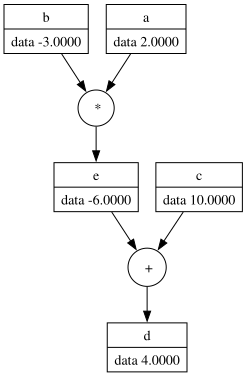

In [35]:
draw_dot(d)

In [36]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label='e'
d = e + c; d.label='d'
f = Value(-2.0, label='f')
L =  d * f ; L.label='L'
L

Value(data=-8.0)

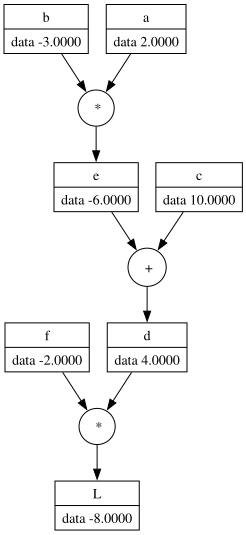

In [37]:
draw_dot(L)

# **Backpropagation - Example 1** 

##### Now that we have built the graph, the next step is to start with the back propagation.
##### In this we start at the end and revesre and calculate the gradient along all the values(f,d,e,c,b,a)
##### Compute the derivative of the value with respect to L. for example derivative of e with respect to L
##### This derivative variable will be called as grad




#### Note: 

##### a,b are inputs that can be called as weights
##### c,d,e are intermediate notdes 
##### L is the loss or the error value that is trying to minimise 
##### h is a tiny nudge temporarily use to test the slope 


In [38]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')
        return out


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label='e'
d = e + c; d.label='d'
f = Value(-2.0, label='f')
L =  d * f ; L.label='L'
L

Value(data=-8.0)

In [39]:
from graphviz import Digraph

def trace(root):
    # This function will traverse the graph of Value objects and return a set of all the Value objects in the graph.
    # build a set of all the Value objects in the graph by traversing the graph using depth first search.
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    # This function will draw the graph of Value objects using graphviz.
    dot = Digraph(format='svg', graph_attr={'rankdir': 'TB'}) # create a new Digraph object with left to right layout, LR means left to right. TB means top to bottom.
    nodes, edges = trace(root) # get the nodes and edges of the graph
    for n in nodes:
        uid = str(id(n)) # get the unique id of the node
        # for any node n, we will create a record shape with the label being the label of the node and the data of the node. 
        # The label will be in the format of {label | data}. The shape will be a record shape which is a rectangle with a horizontal line in the middle. 
        # The top half will contain the label and the bottom half will contain the data.
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record') # add the node to the graph
        if n._op:
            # if this value is a result of an operation, add a node for the operation and connect it to the value node. 
            # The operation node will be a circle with the label being the operation.
            dot.node(name=uid + n._op, label=n._op, shape='circle') # add the operation to the graph
            dot.edge(uid + n._op, uid) # add an edge from the operation to the node
    for n1, n2 in edges:
        # for each edge in the graph, add an edge from the child to the parent. 
        # The edge will be from the child node to the operation node and then from the operation node to the parent node.
        dot.edge(str(id(n1)), str(id(n2)) + n2._op) # add an edge from the child to the parent
    return dot

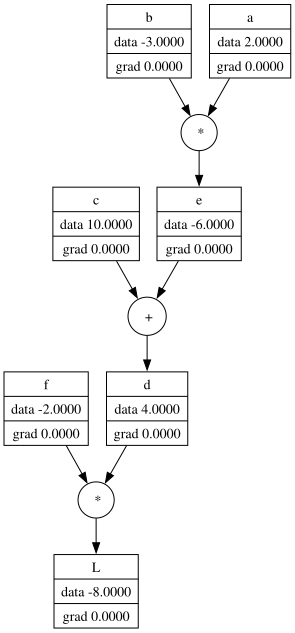

In [40]:
draw_dot(L)

##### In the first step the gradient of every input node, intermediate node and the output node are 0.0000
##### In the next step we begin with finding the gradient of L


In [41]:
type(L)

__main__.Value

### An example to check the derivative with repect to a, skip it for now if getting confused 

In [42]:
# Hre we are going to check the slope of the function L with respect to a,b,c and f. 
# This is done by slightly changing the value of a,b,c and f and checking how much the value of L changes. 
# This change in L is then normalised by the change in a,b,c and f to get the slope.

# Now to begin with we will check the slope of the function L with respect to a. 
# This is done by slightly changing the value of a and checking how much the value of L changes. 
# This change in L is then normalised by the change in a to get the slope.

# From the result it is clear that the slope of the function L with respect to a is -6.0.

def lol():

    h = 0.0001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 + h, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()

6.000000000021544


## Starting backpropagation from L

In [43]:
# Now in the next step we change L by h and see what the derivative is 

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L2 = L.data + h 

    print((L2-L1)/h)

lol()

1.000000000000334


#### The output above is can be explained as ((L+h)-L)/h = h/h = 1.0 
#### Also we know that the derivative of anything with respect to itself is 1 
#### So to find the gradient at the node L we have to derive L with respect to L and the result is 1.0 

#### From the above explanation we can manually set L.grad = 1.0

In [44]:
L.grad = 1.0

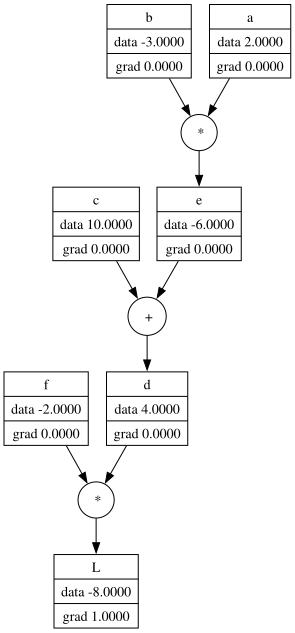

In [45]:
# Redraw the graph now
draw_dot(L)

## Back propagation on the next intermediate node d and f which is derivative of L with respect to d and f 

#### Now the next step is to check the derivative of L with respect to d and f 

#### We know that L = d*f 

#### To find the derivative of L with respect to d which is dL/dd
#### Now to manually calculate the dervative we can use the formula (f(x+h)-f(x))/h where limit h->0
#### f(x+h) = (d+h)*f. because we are finding the derivative with respect to d, we must add h directly to $d$ before the multiplication happens.
#### f(x) = d*f

#### So now the formula becomes 
#### ((d+h) * f - d * f)/h 
####  = (d * f) + (h * f) - (d*f)/h
####  = h*f / h
####  = f



#### So now we know that dL/dd  = f = -2.0000
#### simillerly  dL/df = d = 4.0000



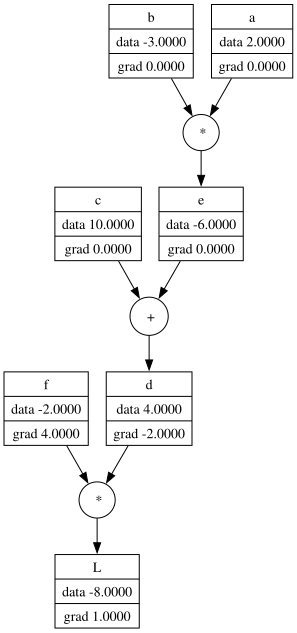

In [46]:
# now this can be added to the graph
f.grad = 4.0
d.grad = -2.0

draw_dot(L)


#### Now we have manually checked and updated the graph. However we check this on the code 

In [47]:
# check the derivative of L with respect to f , check the result which is almost 4 

def lol():

    h = 0.0001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0 + h, label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()

3.9999999999995595


In [48]:
# check the derivative of L with respect to d 

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    d.data += h
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()

-2.000000000000668


## Back propagation on the next intermediate node c and e , thet is derivative of L with respect to c and e 

##### To begin with we can now check the derivative of L with respect to c which is dL/dc
##### Now we need to know how does c impact L through d
##### Now to understand we need to know the impact of c is having on d and the impact of d is having on L and put these information together to get the impact of c on L 


##### Now we already know derivative of L with respect to d 
##### so the next step is to find derivative of d with respect to c or dd/dc 

##### d = c + e 

##### now we can use the definition of a derivative 
##### (f ( x + h ) - f ( x ) ) / h where limit h->0

##### f( x + h ) = c + h + e
##### f(x)   = c + e


##### (f ( x + h ) - f ( x ) ) / h  = ((c + h + e) - (c + e)) / h
#####                               = (c + h + e - c - e) / h
#####                               = h / h
#####                               = 1.0


##### simillerly dd/de = 1.0

### **Now the local derivatives are**

#####  dd/dc = 1.0
#####  dd/de = 1.0





### Chain Rule (Calculus)

#### To check the impact of C on  L we put the imformation together with the help of the chain rule in calculus 
#### Reference for chain rule is given in
#### 1. https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/chain_rule_equation_ref.png
#### 2. https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/chain_rule_example_problem.png

#### Our aim here is to calculate  dL / dc  which is the impact of c on L 
#### dL / dc = (dL / dd) * (dd / dc)
#### from the previous steps we know that 
#### dL / dd = -2.0000
#### dd / dc = 1.0
#### dL / dc = -2.0000 * 1.0 = -2.0000


#### Simillerly the impact of e on L can be calculated as 
#### dL / de = (dL / dd) * (dd / de) 
#### dL / dd = -2.0000
#### dd / de = 1.0
#### dL / de = -2.0000 * 1.0 = -2.0000

In [49]:
c.grad = -2.0
e.grad = -2.0

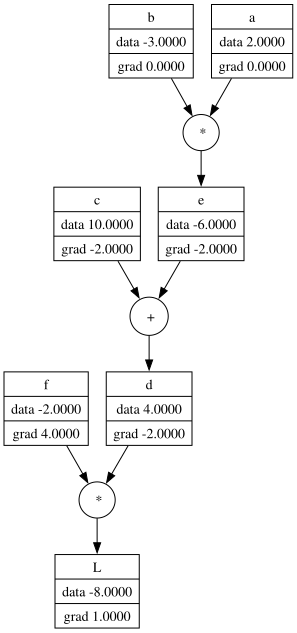

In [50]:
draw_dot(L)

In [51]:
# Now we check and varify the results for change of L with respect to c

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    c.data += h
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()


-1.9999999999988916


In [52]:
# Now we check and varify the results for change of L with respect to e

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    e.data += h
    d = e + c; d.label='d'
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()


-2.000000000000668


## Now as the last step we will be finding out the change of L with respect to a and b 

#### Here we again use the chain rule 

#### dL / da = (dL / de) * (de / da)
#### = ((dL / dd) * (dd / de)) *  (de / da)

#### Now we already know the value for (dL / dd) * (dd / de) = -2.0
#### The next step will be to find out the value of de / da

#### e = a * b 

#### use the formula (f(x+h)-f(x))/h where limit h->0

#### f(x+h) = ( a + h ) * b 
#### f(x) = a*b
#### (f(x+h)-f(x))/h = (( a + h ) * b  - a*b) / h
#### = ( a * b + h * b - a * b)/h
#### = h * b / h
#### = b 
#### = -3.0 = de / da

#### simillerly dL / db = a  = 2.0


#### dL / da = (dL / de) * (de / da) = -2.0 * -3.0
#### dL / db = (dL / de) * (de / db) = -2.0 * 2.0


In [53]:
a.grad = -2.0 * -3.0
b.grad = -2.0 * 2.0

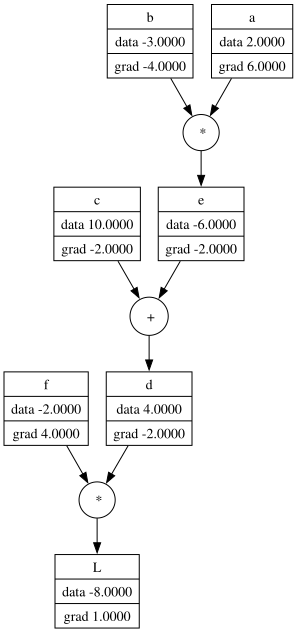

In [54]:
draw_dot(L)

In [55]:
# Now we can cross checkm the answers 
# Change of L with respect to a 

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    a.data += h
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()




6.000000000000227


In [56]:
# Now we can cross checkm the answers 
# Change of L with respect to b 

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    b.data += h
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()


-3.9999999999995595


| Variable | Data (Forward Pass) | Grad (Backward Pass) | What the `.grad` means |
| :--- | :---: | :---: | :--- |
| **`a`** | `-4.0` | **`-6.0`** | If you increase `a` by a tiny bit, `d` will *decrease* by 6 times that amount. |
| **`b`** | `2.0` | **`-4.0`** | If you increase `b` by a tiny bit, `d` will *decrease* by 4 times that amount. |
| **`c`** | `-2.0` | **`-4.0`** | If you increase intermediate node `c` by a tiny bit, `d` will *decrease* by 4 times that amount. |
| **`d`** | `8.0` | **`1.0`** | The starting point of the backward pass (baseline sensitivity of the final output). |

## In the next step we can try to make L grow up by making changes in the direction of the gradient 

#### we make changes in the leaf nodes which have control over


In [57]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad


# rewrite the forward pass 

e = a * b
d = e + c
L = d * f

print(L.data)

-7.286496


### The gradient hands  two crucial pieces of information for every single variable in your code:

##### 1. The Sign (Plus or Minus): It tells you with 100% certainty whether increasing or decreasing that specific variable will push the final error down. You no longer have to guess.

##### 2. The Magnitude (The Size of the Number): It tells you how much leverage that variable has. If a gradient is huge, you know that tweaking that specific weight will have a massive impact on fixing your mistake.

# **Backpropagation Example 2 - Backpropagate through neuron , Neurons, Convolutional Neural Networks** 
#### Reference Image: https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/neuron_ref_img.png

#### x : inputs 
#### w : weights 
#### b : bias 
#### f : activation function

#### Synapses will be multiplicative (eg: wx)

#### Activation function example - tanh


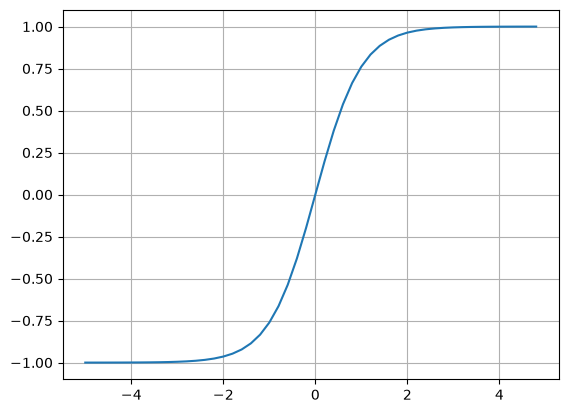

In [58]:
plt.plot(np.arange(-5,5,0.2),np.tanh(np.arange(-5,5,0.2)));plt.grid();

#### Now lets build a simple neural network

In [71]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.7, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'



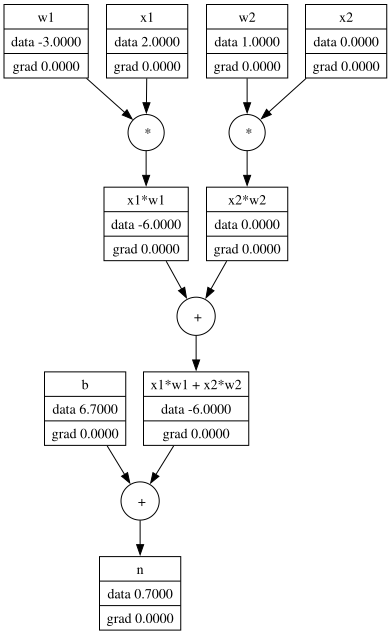

In [72]:
draw_dot(n)

#### The next step is to add the activation function to n, however we havent defined it, so we make a new function inside the class value to perform the tanh activation 

#### Ref img for tanh: https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/tanh_ref_img.png

In [73]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')
        return out


In [ ]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.7, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'


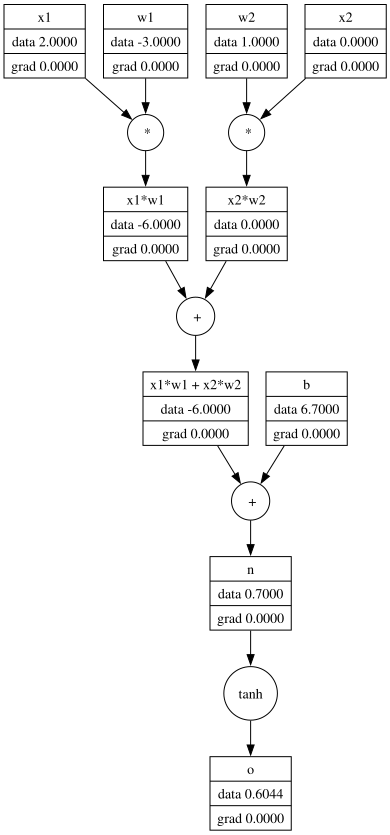

In [75]:
draw_dot(o)

#### The activation function is used to squash the output from the neuron and the output of tanh will go as a straight line after -1 and 1
#### As a next step we can try to change the bias and se what chnages is happenig to the output 


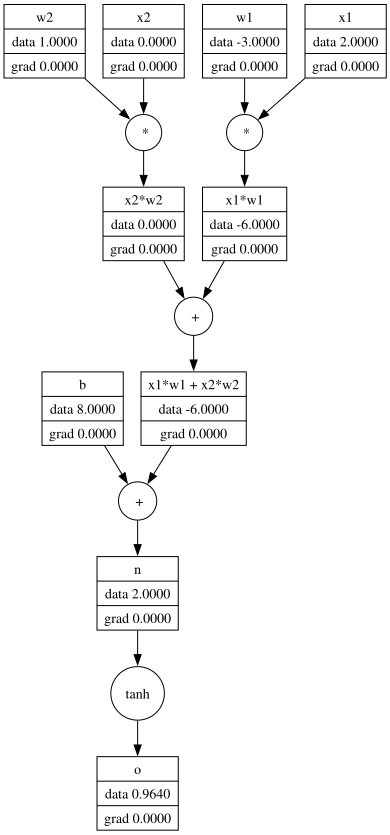

In [77]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(8.0, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'

draw_dot(o)


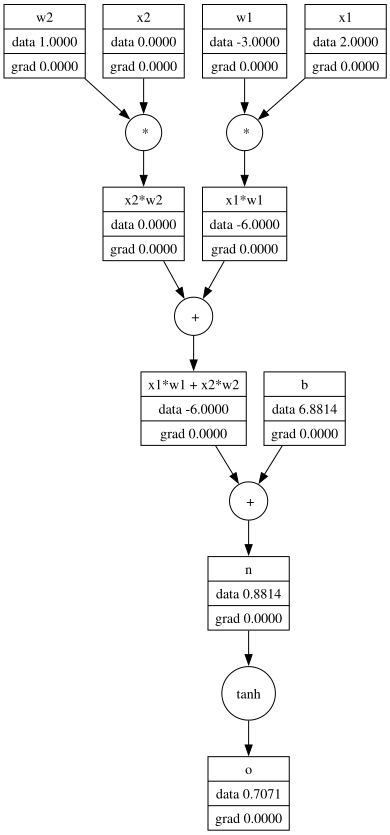

In [78]:
# change the bias again (just to get good values when doing backpropagation)


# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'

draw_dot(o)



### Now lets start with the backpropagation on the tiny neuron that we have creared 

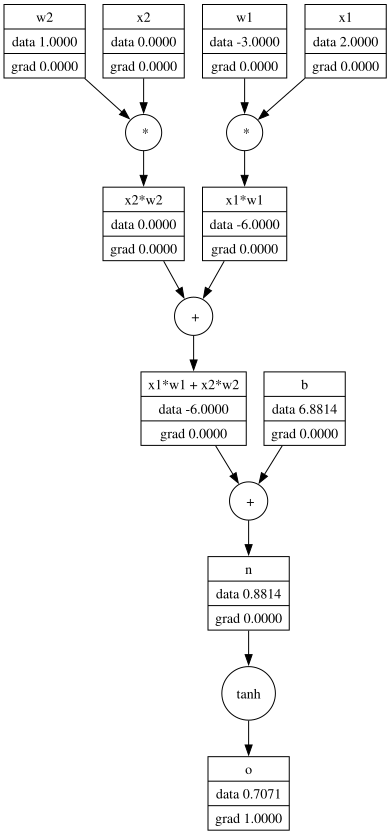

In [81]:
# To begin with, lets start from o and later find the derivative of o with respect to all the inputs in the neural network 
# so derivative of o with respect to o is 1.0 because the change in o with respect to o is 1.0. This is the base case for backpropagation.
o.grad = 1.0
draw_dot(o)


## **backpropagate through tanh** 
#### o = tanh(n)
#### do/dn = 1 - tanh(n)**2.  ref : 
#### do/hn = 1 - o**2 

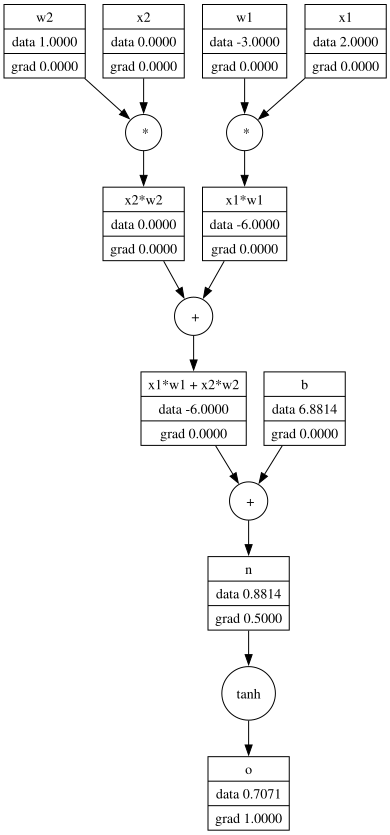

In [84]:
# do/hn = 1 - o**2 
n.grad = 1 - o.data**2
draw_dot(o)


## **Continue the backpropagation and find out derivative of n with respect to x1w1x2w2 and b.**
#### now we know from the previous example thr plus sign is a distributor 
#### derivative of n with respect to x1w1 + x2w2  and  b 

#### Now according to the formula for the derivatives 
##### (f ( x + h ) - f ( x ) ) / h where limit h->0

#### derivative of n with respect to x1w1 + x2w2
#### f( x + h ) = x1w1 + x2w2 + h 
#### f(x)   = x1w1 + x2w2
#### (f ( x + h ) - f ( x ) ) / h = ((x1w1 + x2w2 + h ) - (x1w1 + x2w2)) / h
####  = x1w1 + x2w2 + h - x1w1 - x2w2 / h 
####  = h/h
####  = 1


#### derivative of n with respect to b 
#### f( x + h ) = b + h
#### f(x) = b
#### (f ( x + h ) - f ( x ) ) / h = ((b+h) - b ) / h 
#### = h/h
#### = 1


#### Now lets add the chain rule to get the derivative of o with respect to x1w1+x2w1
#### d(x1w1 + x2w1) / do = (do/dn) * (dn / d(x1w1+x2w1)) = 0.5 * 1.0 = 0.5

#### similerly derivative of o with respect to b 
#### d(b) / do = (do/dn) * (dn / d(b)) = 0.5 * 1.0 = 0.5




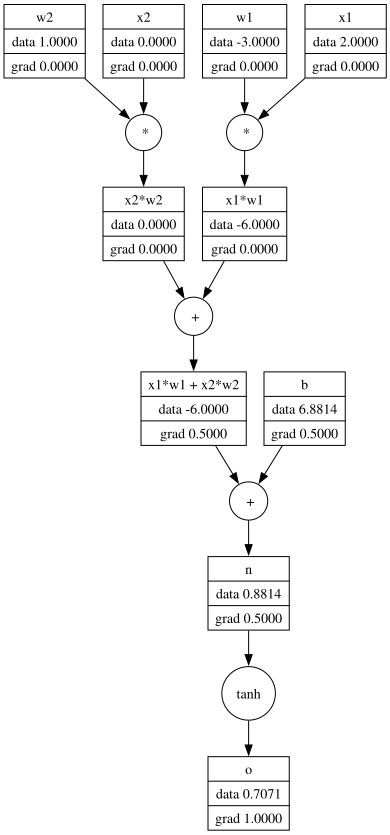

In [86]:
x1w1x2w2.grad = 0.5
b.grad = 0.5
draw_dot(o)



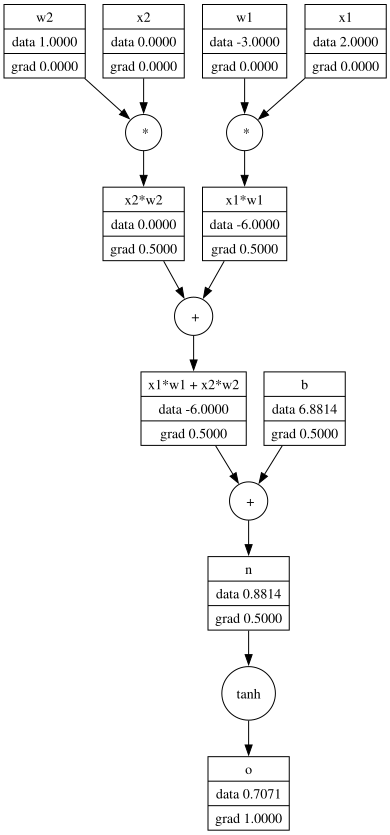

In [87]:
# similer to the above step we can find the derivative of x1w1x2w2 with respect to x1w1 and x2w2. 
# This will be 1.0 because the change in x1w1x2w2 with respect to x1w1 and x2w2 is 1.0. 
# This is because x1w1x2w2 = x1w1 + x2w2. So the change in x1w1x2w2 with respect to x1w1 and x2w2 is 1.0.
# now the derivative of x1w1x2w2 with respect to x1w1 and x2w2 is 0.5 because the change in x1w1x2w2 with respect to x1w1 and x2w2 is 0.5.
x1w1.grad = 0.5
x2w2.grad = 0.5
draw_dot(o)

## **Find the impact of x1 on o (the derivative: do / dx1)**

#### The full Chain Rule backward through the computational graph
#### do / dx1 = (do / dn) * (dn / d(x1 * w1 + x2 * w2 + b)) * (d(x1 * w1 + x2 * w2 + b) / d(x1 * w1)) * (d(x1*w1) / dx1)
#### Where n = (x1 * w1 + x2 * w2) + b

#### Break down each local derivative node-by-node
#### 1. do / dn = 1 - o** 2 = 1 - (0.7071)**2 = 0.5                   (Derivative of tanh activation)
#### 2. dn / d(x1 * w1 + x2 * w2 + b) = 1.0                   (Local derivative of addition)
#### 3. d(x1 * w1 + x2 * w2 + b) / d(x1*w1) = 1.0             (Local derivative of addition)
#### 4. d(x1*w1) / dx1 = w1                 (Local derivative of multiplication w.r.t x1)


#### Expanding the Local Derivative: d(x1 * w1) / dx1 = w1
#### f(x1) = x1 * w1
#### Apply the limit definition of a derivative: f'(x) = lim (h -> 0) [ f(x1 + h) - f(x1) ] / h
#### =  [ (x1 + h) * w1 - (x1 * w1) ] / h
#### = [ (x1 * w1 + h * w1) - (x1 * w1) ] / h
#### = [ h * w1 ] / h
#### = w1


#### do / dx1 = 0.5 * 1.0 * 1.0 * (-3.0) = -1.5

In [88]:
x1.grad = -1.5

## **Find the impact of w1 on o (the derivative: do / dw1)**

#### The full Chain Rule backward through the computational graph
#### do / dw1 = (do / dn) * (dn / d(x1 * w1 + x2 * w2 + b)) * (d(x1 * w1 + x2 * w2 + b) / d(x1*w1)) * (d(x1*w1) / dw1)
#### Where n = (x1 * w1 + x2 * w2) + b

#### Break down each local derivative node-by-node
#### 1. do / dn = 1 - o** 2 = 1 - (0.7071)**2 = 0.5                   (Derivative of tanh activation)
#### 2. dn / d(x1 * w1 + x2 * w2 + b) = 1.0                   (Local derivative of addition)
#### 3. d(x1 * w1 + x2 * w2 + b) / d(x1*w1) = 1.0             (Local derivative of addition)
#### 4. d(x1*w1) / dw1 = x1                 (Local derivative of multiplication w.r.t w1)


#### Expanding the Local Derivative: d(x1 * w1) / dw1 = x1
#### f(w1) = x1 * w1
#### Apply the limit definition of a derivative: f'(w) = lim (h -> 0) [ f(w1 + h) - f(w1) ] / h
#### =  [ x1 * (w1 + h) - (x1 * w1) ] / h
#### = [ (x1 * w1 + x1 * h) - (x1 * w1) ] / h
#### = [ x1 * h ] / h
#### = x1


#### do / dw1 = 0.5 * 1.0 * 1.0 * (2.0) = 1.0

In [89]:
w1.grad = 1.0



## **Find the impact of x2 on o (the derivative: do / dx2)**

#### The full Chain Rule backward through the computational graph
#### do / dx2 = (do / dn) * (dn / d(x1 * w1 + x2 * w2 + b)) * (d(x1 * w1 + x2 * w2 + b) / d(x2*w2)) * (d(x2*w2) / dx2)
#### Where n = (x1 * w1 + x2 * w2) + b

#### Break down each local derivative node-by-node
#### 1. do / dn = 1 - o** 2 = 1 - (0.7071)**2 = 0.5                   (Derivative of tanh activation)
#### 2. dn / d(x1 * w1 + x2 * w2 + b) = 1.0                   (Local derivative of addition)
#### 3. d(x1 * w1 + x2 * w2 + b) / d(x2*w2) = 1.0             (Local derivative of addition)
#### 4. d(x2*w2) / dx2 = w2                 (Local derivative of multiplication w.r.t x2)


#### Expanding the Local Derivative: d(x2 * w2) / dx2 = w2
#### f(x2) = x2 * w2
#### Apply the limit definition of a derivative: f'(x) = lim (h -> 0) [ f(x2 + h) - f(x2) ] / h
#### =  [ (x2 + h) * w2 - (x2 * w2) ] / h
#### = [ (x2 * w2 + h * w2) - (x2 * w2) ] / h
#### = [ h * w2 ] / h
#### = w2


#### do / dx2 = 0.5 * 1.0 * 1.0 * (1.0) = 0.5

In [90]:
x2.grad = 0.5

## **Find the impact of w2 on o (the derivative: do / dw2)**

#### The full Chain Rule backward through the computational graph
#### do / dw2 = (do / dn) * (dn / d(x1 * w1 + x2 * w2 + b)) * (d(x1 * w1 + x2 * w2 + b) / d(x2*w2)) * (d(x2*w2) / dw2)
#### Where n = (x1 * w1 + x2 * w2) + b

#### Break down each local derivative node-by-node
#### 1. do / dn = 1 - o** 2 = 1 - (0.7071)**2 = 0.5                   (Derivative of tanh activation)
#### 2. dn / d(x1 * w1 + x2 * w2 + b) = 1.0                   (Local derivative of addition)
#### 3. d(x1 * w1 + x2 * w2 + b) / d(x2*w2) = 1.0             (Local derivative of addition)
#### 4. d(x2*w2) / dw2 = x2                 (Local derivative of multiplication w.r.t w2)


#### Expanding the Local Derivative: d(x2 * w2) / dw2 = x2
#### f(w2) = x2 * w2
#### Apply the limit definition of a derivative: f'(w) = lim (h -> 0) [ f(w2 + h) - f(w2) ] / h
#### =  [ x2 * (w2 + h) - (x2 * w2) ] / h
#### = [ (x2 * w2 + x2 * h) - (x2 * w2) ] / h
#### = [ x2 * h ] / h
#### = x2


#### do / dw2 = 0.5 * 1.0 * 1.0 * (0.0) = 0.0

In [91]:
w2.grad = 0.0

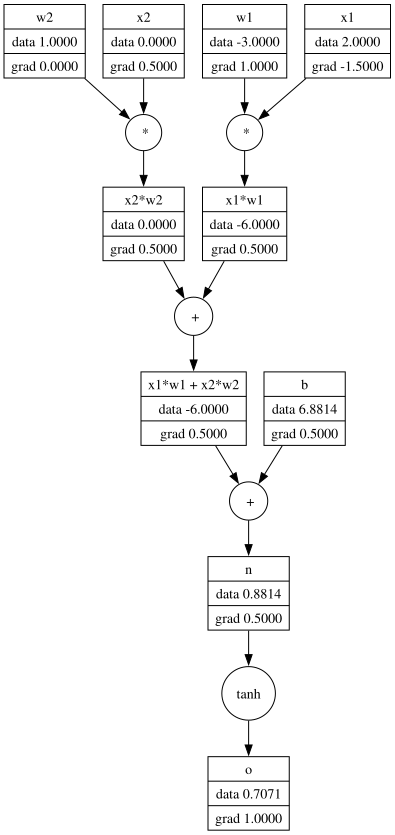

In [92]:
draw_dot(o)

## **Automating Backpropagation through the code**

In [93]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._backward = lambda: None # this will store the function that will be used to compute the gradient of the Value object. This is a placeholder for now.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')

        def _backward():
            self.grad = 1.0 * out.grad
            other.grad = 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')

        def _backward():
            self.grad = other.data * out.grad
            other.grad = self.data * out.grad

        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        
        return out


In [94]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'

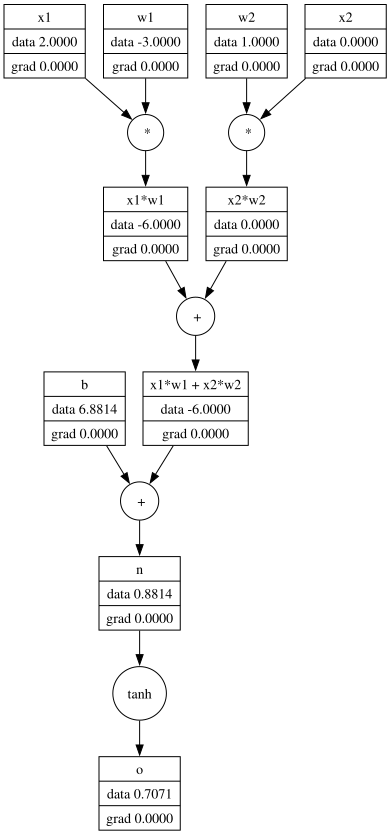

In [95]:
draw_dot(o)

In [96]:
o.grad = 1.0
o._backward()

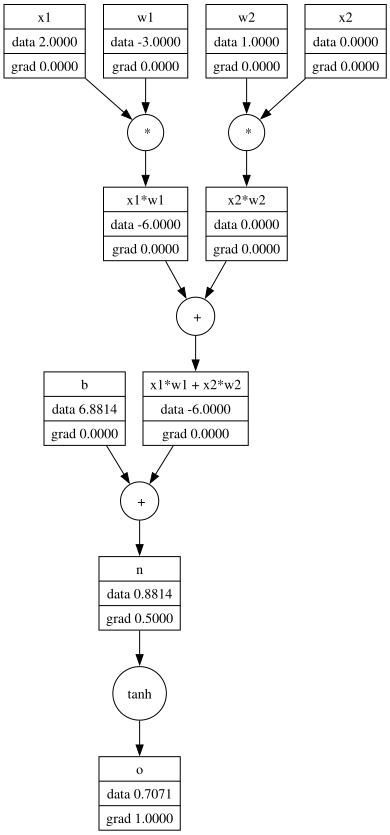

In [97]:
draw_dot(o)

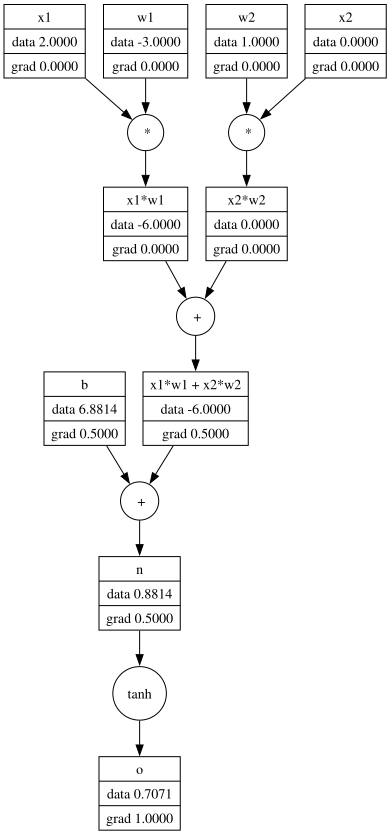

In [100]:
n._backward()
draw_dot(o)

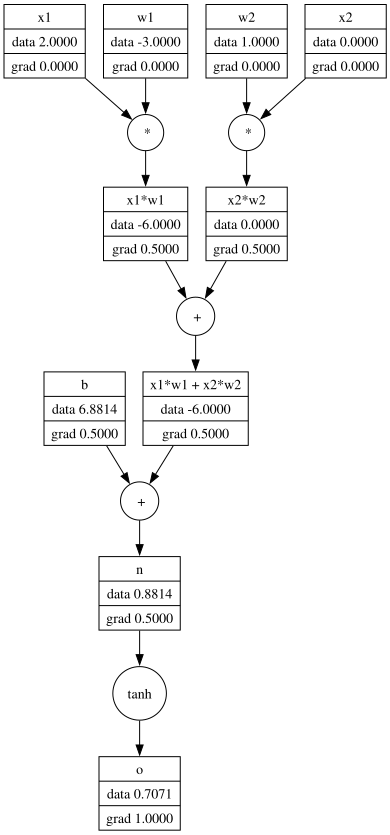

In [102]:
x1w1x2w2._backward()
draw_dot(o)

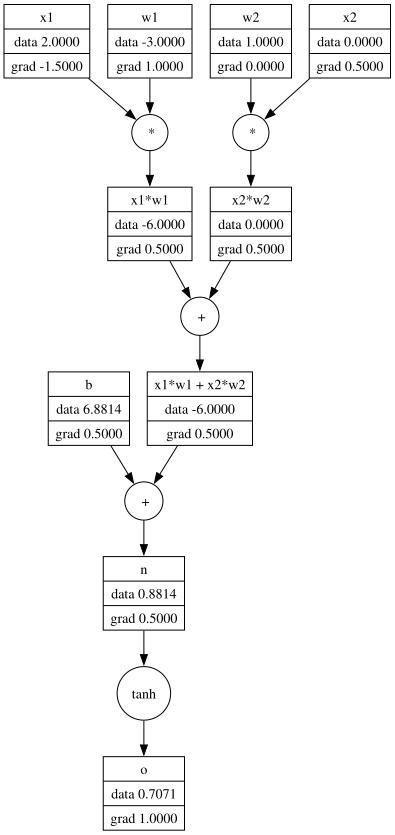

In [103]:
x1w1._backward()
x2w2._backward()
draw_dot(o)

## **Topological Sort**

#### A way to laying out a graph so that all the edges can only go from left to right 
#### ref img : 

In [107]:
# code to build a topological graph

topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=6.881373587019543),
 Value(data=0.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=2.0),
 Value(data=-3.0),
 Value(data=-6.0),
 Value(data=-6.0),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [104]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._backward = lambda: None # this will store the function that will be used to compute the gradient of the Value object. This is a placeholder for now.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')

        def _backward():
            self.grad = 1.0 * out.grad
            other.grad = 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')

        def _backward():
            self.grad = other.data * out.grad
            other.grad = self.data * out.grad

        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        
        return out


In [105]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'

In [106]:
o.grad = 1.0

In [108]:
# code to build a topological graph

topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)

for node in reversed(topo):
    node._backward()

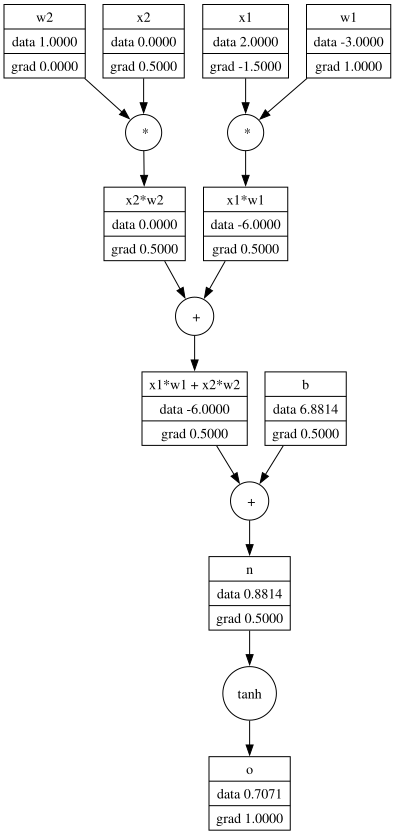

In [109]:
draw_dot(o)

## Add backward in the Value class so that the code will automatically go throgh the values and give the resulst without calling  topo and backward 

In [110]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._backward = lambda: None # this will store the function that will be used to compute the gradient of the Value object. This is a placeholder for now.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')

        def _backward():
            self.grad = 1.0 * out.grad
            other.grad = 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')

        def _backward():
            self.grad = other.data * out.grad
            other.grad = self.data * out.grad

        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()    



In [111]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'

In [112]:
o.backward()

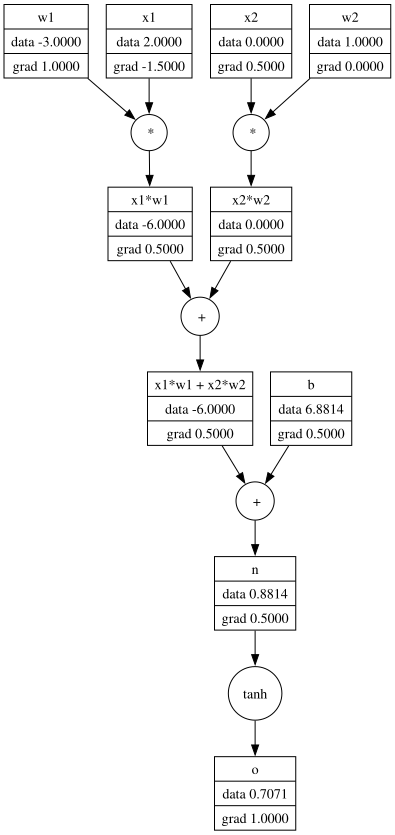

In [113]:
draw_dot(o)

## Fixing the bug 

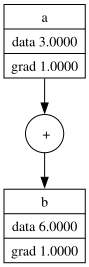

In [114]:
a = Value(3.0, label='a')
b = a + a ; b.label = 'b'
b.backward()
draw_dot(b)

#### in the above result the derivative of a with respect to a is 1 however the derivative of b with respect to a should be 2
#### This issue will occur any time the same variable is used more than once 


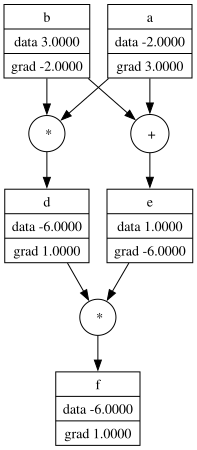

In [115]:
a = Value(-2.0, label='a')
b = Value(3.0, label='b')
d = a * b; d.label = 'd'
e = a + b; e.label = 'e'
f = d * e; f.label = 'f'

f.backward()
draw_dot(f) 


In [116]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._backward = lambda: None # this will store the function that will be used to compute the gradient of the Value object. This is a placeholder for now.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()    



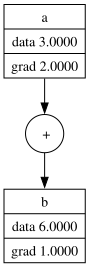

In [117]:
a = Value(3.0, label='a')
b = a + a ; b.label = 'b'
b.backward()
draw_dot(b)

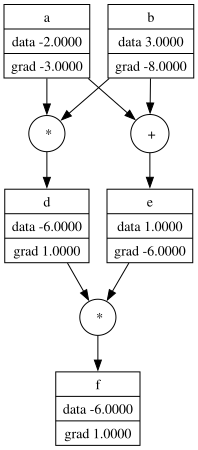

In [118]:
a = Value(-2.0, label='a')
b = Value(3.0, label='b')
d = a * b; d.label = 'd'
e = a + b; e.label = 'e'
f = d * e; f.label = 'f'

f.backward()
draw_dot(f) 


## **Trying to impliment the exponentiation equation of tanh**

#### Before implimenting the exponentiation some of the drwabacks of the code needs to overcome 
#### Now that the code will only take value objects and perform operations in it 
#### supposewe want to add an integer to the value object it will show error 

In [ ]:
# a = Value(2.0)
# a+1

AttributeError: 'int' object has no attribute 'data'

#### to make the code more convenient a few more changes will be done on the code 

In [120]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._backward = lambda: None # this will store the function that will be used to compute the gradient of the Value object. This is a placeholder for now.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children=(self, other), _op=' +')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, _children=(self, other), _op=' *')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()    



#### Now the code will work for addition and multiplication
#### the next example will show another drawback of the code 

In [121]:
a = Value(2.0)
a*2

Value(data=4.0)

In [ ]:
# 2*a

TypeError: unsupported operand type(s) for *: 'int' and 'Value'

#### To solve this a new function __rmul__ will be defined inside the class Value 

In [125]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._backward = lambda: None # this will store the function that will be used to compute the gradient of the Value object. This is a placeholder for now.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children=(self, other), _op=' +')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, _children=(self, other), _op=' *')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __rmul__(self, other): #other * self 
        return self * other

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()    



In [126]:
a = Value(2.0)

2*a

Value(data=4.0)

### The next step will be to impliment the exponentiation part inside the class Value 

In [128]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._backward = lambda: None # this will store the function that will be used to compute the gradient of the Value object. This is a placeholder for now.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children=(self, other), _op=' +')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, _children=(self, other), _op=' *')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __rmul__(self, other): #other * self 
        return self * other

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        def _backward():
            self.grad += out.data.out.grad
        out._backward = _backward
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()    



In [129]:
a =  Value(2.0)
a.exp()

Value(data=7.38905609893065)

### Implimenting division and power 

In [ ]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._backward = lambda: None # this will store the function that will be used to compute the gradient of the Value object. This is a placeholder for now.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children=(self, other), _op=' +')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, _children=(self, other), _op=' *')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __pow__(self,other):
        assert isinstance(other, (int,float)), "only supporting int/float power for now"
        out = Value(self.data**other, (self,),f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other-1)) * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other): #other * self 
        return self * other

    def __truediv__(self,other):
        return self * other**-1

    def __neg__(self,other):
        return self * -1

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        def _backward():
            self.grad += out.data.out.grad
        out._backward = _backward
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()    



In [134]:
a = Value(2.0)
b = Value(4.0)
a / b

Value(data=0.5)

### Adding subtraction function to the class 

In [147]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._backward = lambda: None # this will store the function that will be used to compute the gradient of the Value object. This is a placeholder for now.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children=(self, other), _op=' +')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, _children=(self, other), _op=' *')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __pow__(self,other):
        assert isinstance(other, (int,float)), "only supporting int/float power for now"
        out = Value(self.data**other, (self,),f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other-1)) * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other): #other * self 
        return self * other

    def __truediv__(self,other):
        return self * other**-1

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()    



In [148]:
a = Value(2.0)
b = Value(4.0)
a - b

Value(data=-2.0)

In [149]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'
o.backward()

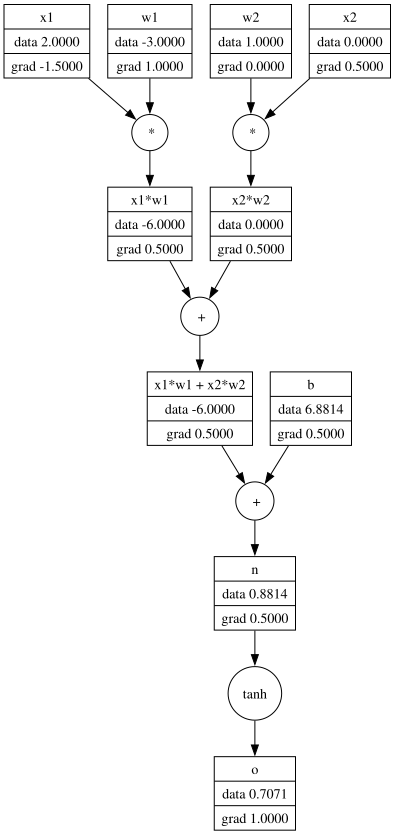

In [143]:
draw_dot(o)

### Break down the tanh to the exp in the inputs 
### Equation reference : 

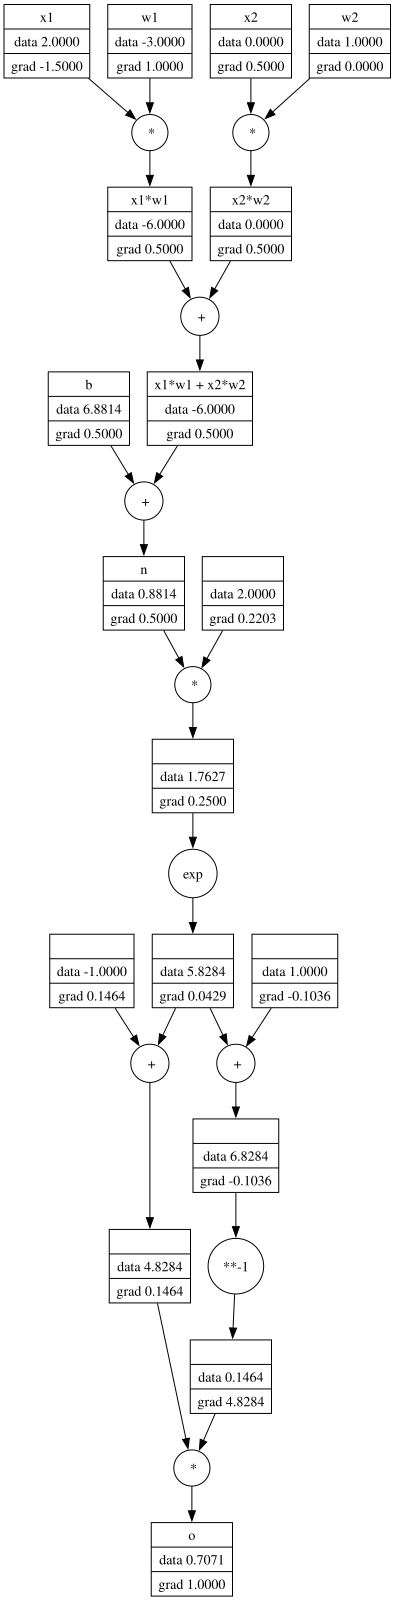

In [150]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'

# Redefining o by using the exponentiation equation of tanh
e = (2*n).exp()
o = (e - 1) / (e + 1)

o.label='o'
o.backward()
draw_dot(o)

## **Implimenting the backpropagation using pytorch**

In [151]:
import torch

### Pytorch will be based on tensors which are n dimentional arrays of sclars


In [152]:
# Example of a tensor 

torch.Tensor([[1, 2, 3], [4, 5, 6]])

tensor([[1., 2., 3.],
        [4., 5., 6.]])

In [153]:
torch.Tensor([[1, 2, 3], [4, 5, 6]]).shape

torch.Size([2, 3])

#### Now we create a tensor that has only a single element and casting it to be double beacuse python usually use double precison for floating point values and to make everything identical use double 
#### The default data type of the value inside tensor is floating point 

In [155]:
torch.Tensor([2.0]).dtype

torch.float32

In [156]:
torch.Tensor([2.0]).double().dtype

torch.float64

### Since python thinks the leaf nodes do not require gradients we need to mention every node require gradientts by giving x.requires_grad = True 

In [157]:
x1 = torch.Tensor([2.0]).double()   ;x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()   ;x2.requires_grad = True

w1 = torch.Tensor([-3.0]).double()   ;w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()   ;w2.requires_grad = True

b = torch.Tensor([6.8813735870195432]).double()   ;b.requires_grad = True

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('______________________________')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
______________________________
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [158]:
o

tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [160]:
o.item()

0.7071066904050358

In [161]:
x2.grad

tensor([0.5000], dtype=torch.float64)

In [162]:
x2.grad.item()

0.5000001283844369

## **Building a neural net using pytorch**

In [163]:
import random

In [166]:
class Neuron:

    def __init__(self, nin): #nin is the number of inputs to the neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # weights of the neuron by randomly selecting the value between -1 and 1 
        self.b = Value(random.uniform(-1,1)) # bias of the neuron by randomly selecting the value between -1 and 1

    def __call__(self,x):
        # w * x +b
        return 0.0

x = [2.0, 3.0]
n = Neuron(2)
n(x)

0.0

### Next step we will try to impliment w*x+b

### the first step will be pairing all the x values with a weight so we use zip. this will create a tuple by taking the one value from x and other value from the weight

In [168]:
# example for printing the results 
class Neuron:

    def __init__(self, nin): #nin is the number of inputs to the neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # weights of the neuron by randomly selecting the value between -1 and 1 
        self.b = Value(random.uniform(-1,1)) # bias of the neuron by randomly selecting the value between -1 and 1

    def __call__(self,x):
        # w * x +b
        print(list(zip(self.w,x))   )
        return 0.0

x = [2.0, 3.0]
n = Neuron(2)
n(x)

[(Value(data=0.7648621583698225), 2.0), (Value(data=0.0442400325515242), 3.0)]


0.0

In [174]:
class Neuron:

    def __init__(self, nin): #nin is the number of inputs to the neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # weights of the neuron by randomly selecting the value between -1 and 1 
        self.b = Value(random.uniform(-1,1)) # bias of the neuron by randomly selecting the value between -1 and 1

    def __call__(self,x):
        # w * x +b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

x = [2.0, 3.0]
n = Neuron(2)
n(x)

Value(data=0.5628865927531492)

### Next we can define a layer of neurons 

In [175]:
class Neuron:

    def __init__(self, nin): #nin is the number of inputs to the neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # weights of the neuron by randomly selecting the value between -1 and 1 
        self.b = Value(random.uniform(-1,1)) # bias of the neuron by randomly selecting the value between -1 and 1

    def __call__(self,x):
        # w * x +b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

class Layer:
    def __init__(self, nin, nout): # nout is the number of outpouts 
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs

x = [2.0, 3.0]
n = Layer(2,3)
n(x)

[Value(data=0.5582845268921475),
 Value(data=0.9993390802666818),
 Value(data=-0.9189199546359481)]

### Now add the multi layer perceprton 
### it will take the number of inpouts and a list of outputs from the neuron and then iterate over the consecutive pairs 

In [178]:
class Neuron:

    def __init__(self, nin): #nin is the number of inputs to the neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # weights of the neuron by randomly selecting the value between -1 and 1 
        self.b = Value(random.uniform(-1,1)) # bias of the neuron by randomly selecting the value between -1 and 1

    def __call__(self,x):
        # w * x +b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

class Layer:
    def __init__(self, nin, nout): # nout is the number of outpouts 
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

class MLP:
    def __init__(self, nin,nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x 

    
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=-0.0173661228705018)

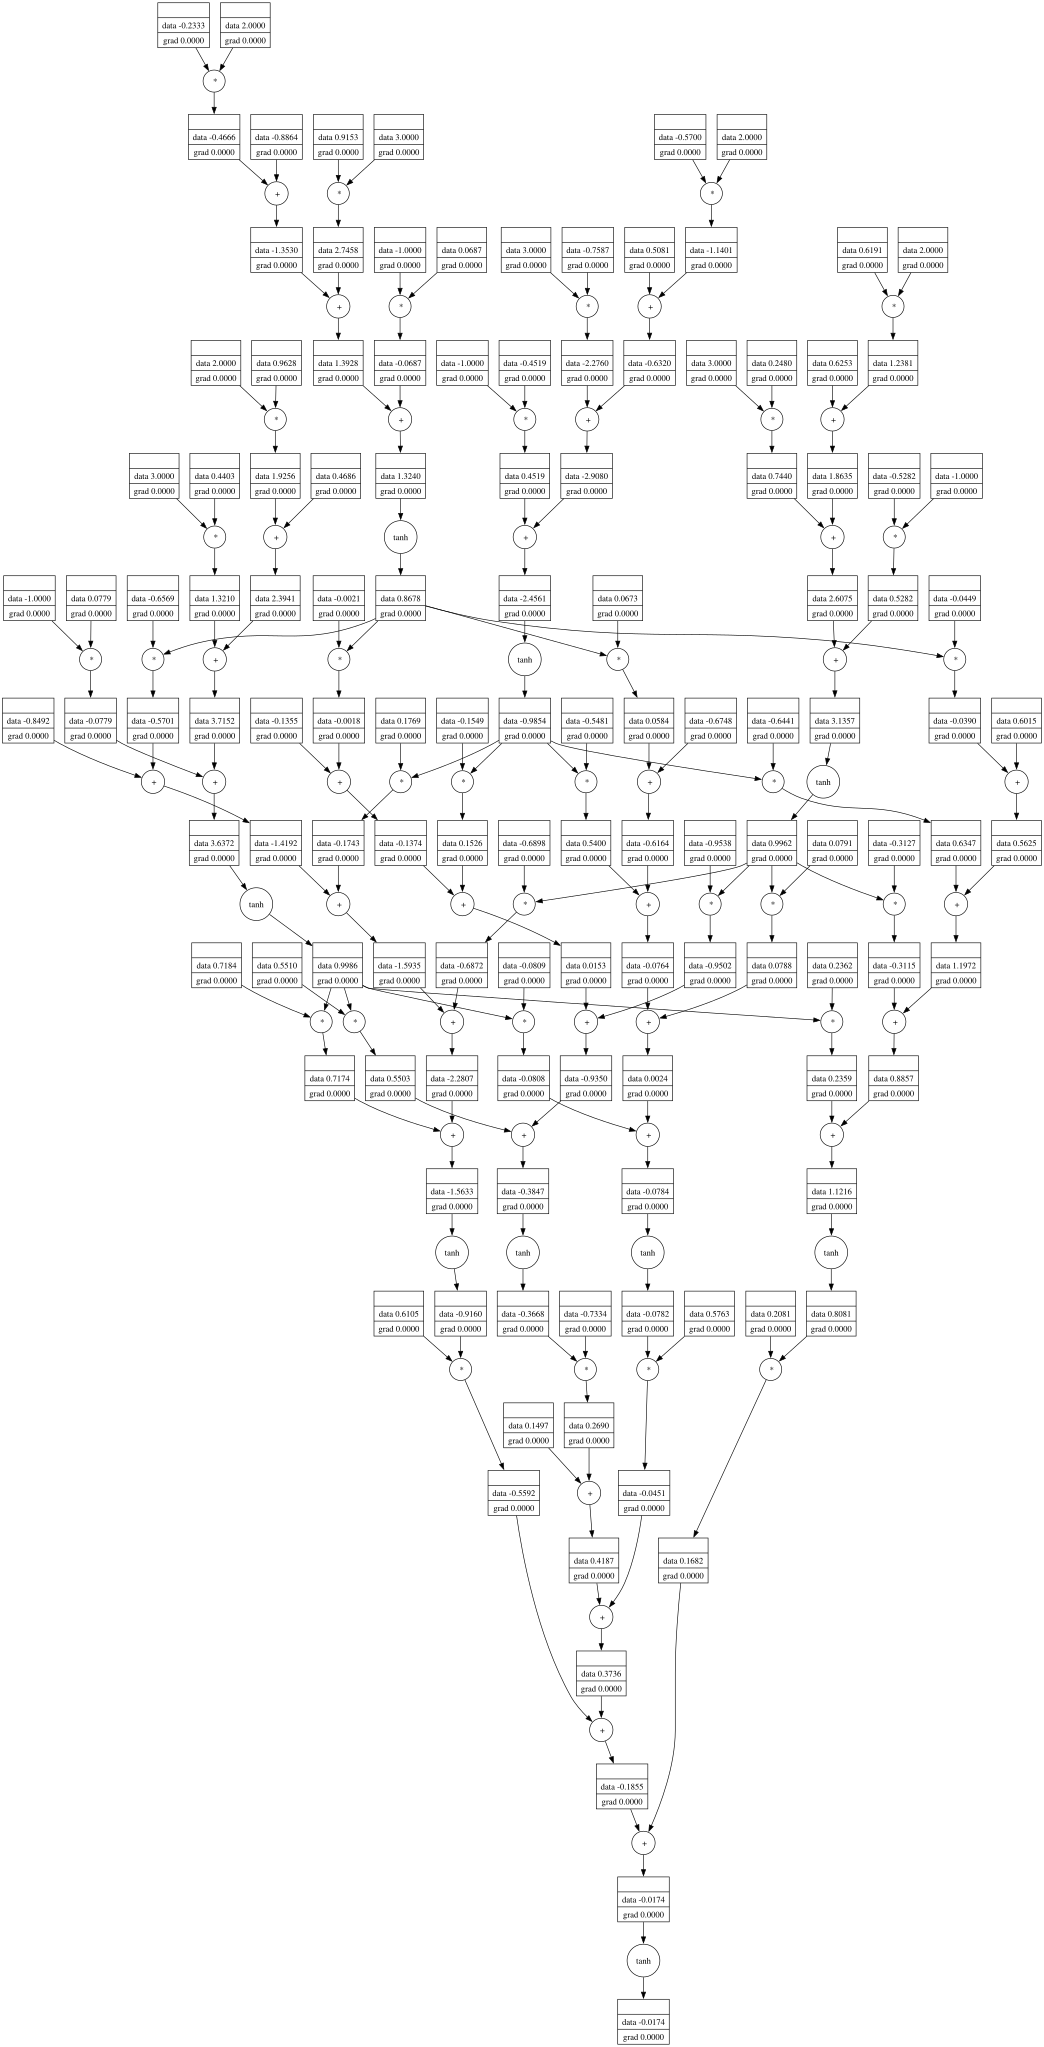

In [179]:
draw_dot(n(x))

### Backpropagate through the neurons created by pytorch 

In [181]:
xs = [  [2.0,3.0,-1.0],
        [3.0,-1.0,0.5],
        [0.5,1.0,1.0],
        [1.0,1.0,-1.0]]

ys = [1.0,-1.0,-1.0,1.0] # desired targets 

ypred = [n(x) for x in xs]
ypred


[Value(data=-0.0173661228705018),
 Value(data=0.20461247211220868),
 Value(data=-0.1673859584191736),
 Value(data=-0.033146497709535795)]

### now the outputs needs some improvements to achieve the targeted outputs 
### This can be acieved using the loss which is a single number that measures the total performance of the neuralnet
### the formula used for this will be [((y_out) - (y_ground_truth))**2]
### when the prediction is exactly the target the result will be zero
### the aim is to reduce the loss and the final loss will be the sum of all the individual losses 

In [185]:
[(yout - ygt)**2 for ygt,yout in zip(ys,ypred)]

[Value(data=1.0350338279645568),
 Value(data=1.4510912079682867),
 Value(data=0.6932461422375581),
 Value(data=1.0673916857294796)]

In [187]:
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))
loss

Value(data=4.246762863899882)

In [188]:
loss.backward()

In [189]:
n.layers[0].neurons[0].w[0]

Value(data=-0.233297588086945)

In [190]:
n.layers[0].neurons[0].w[0].grad

0.21111357814588153

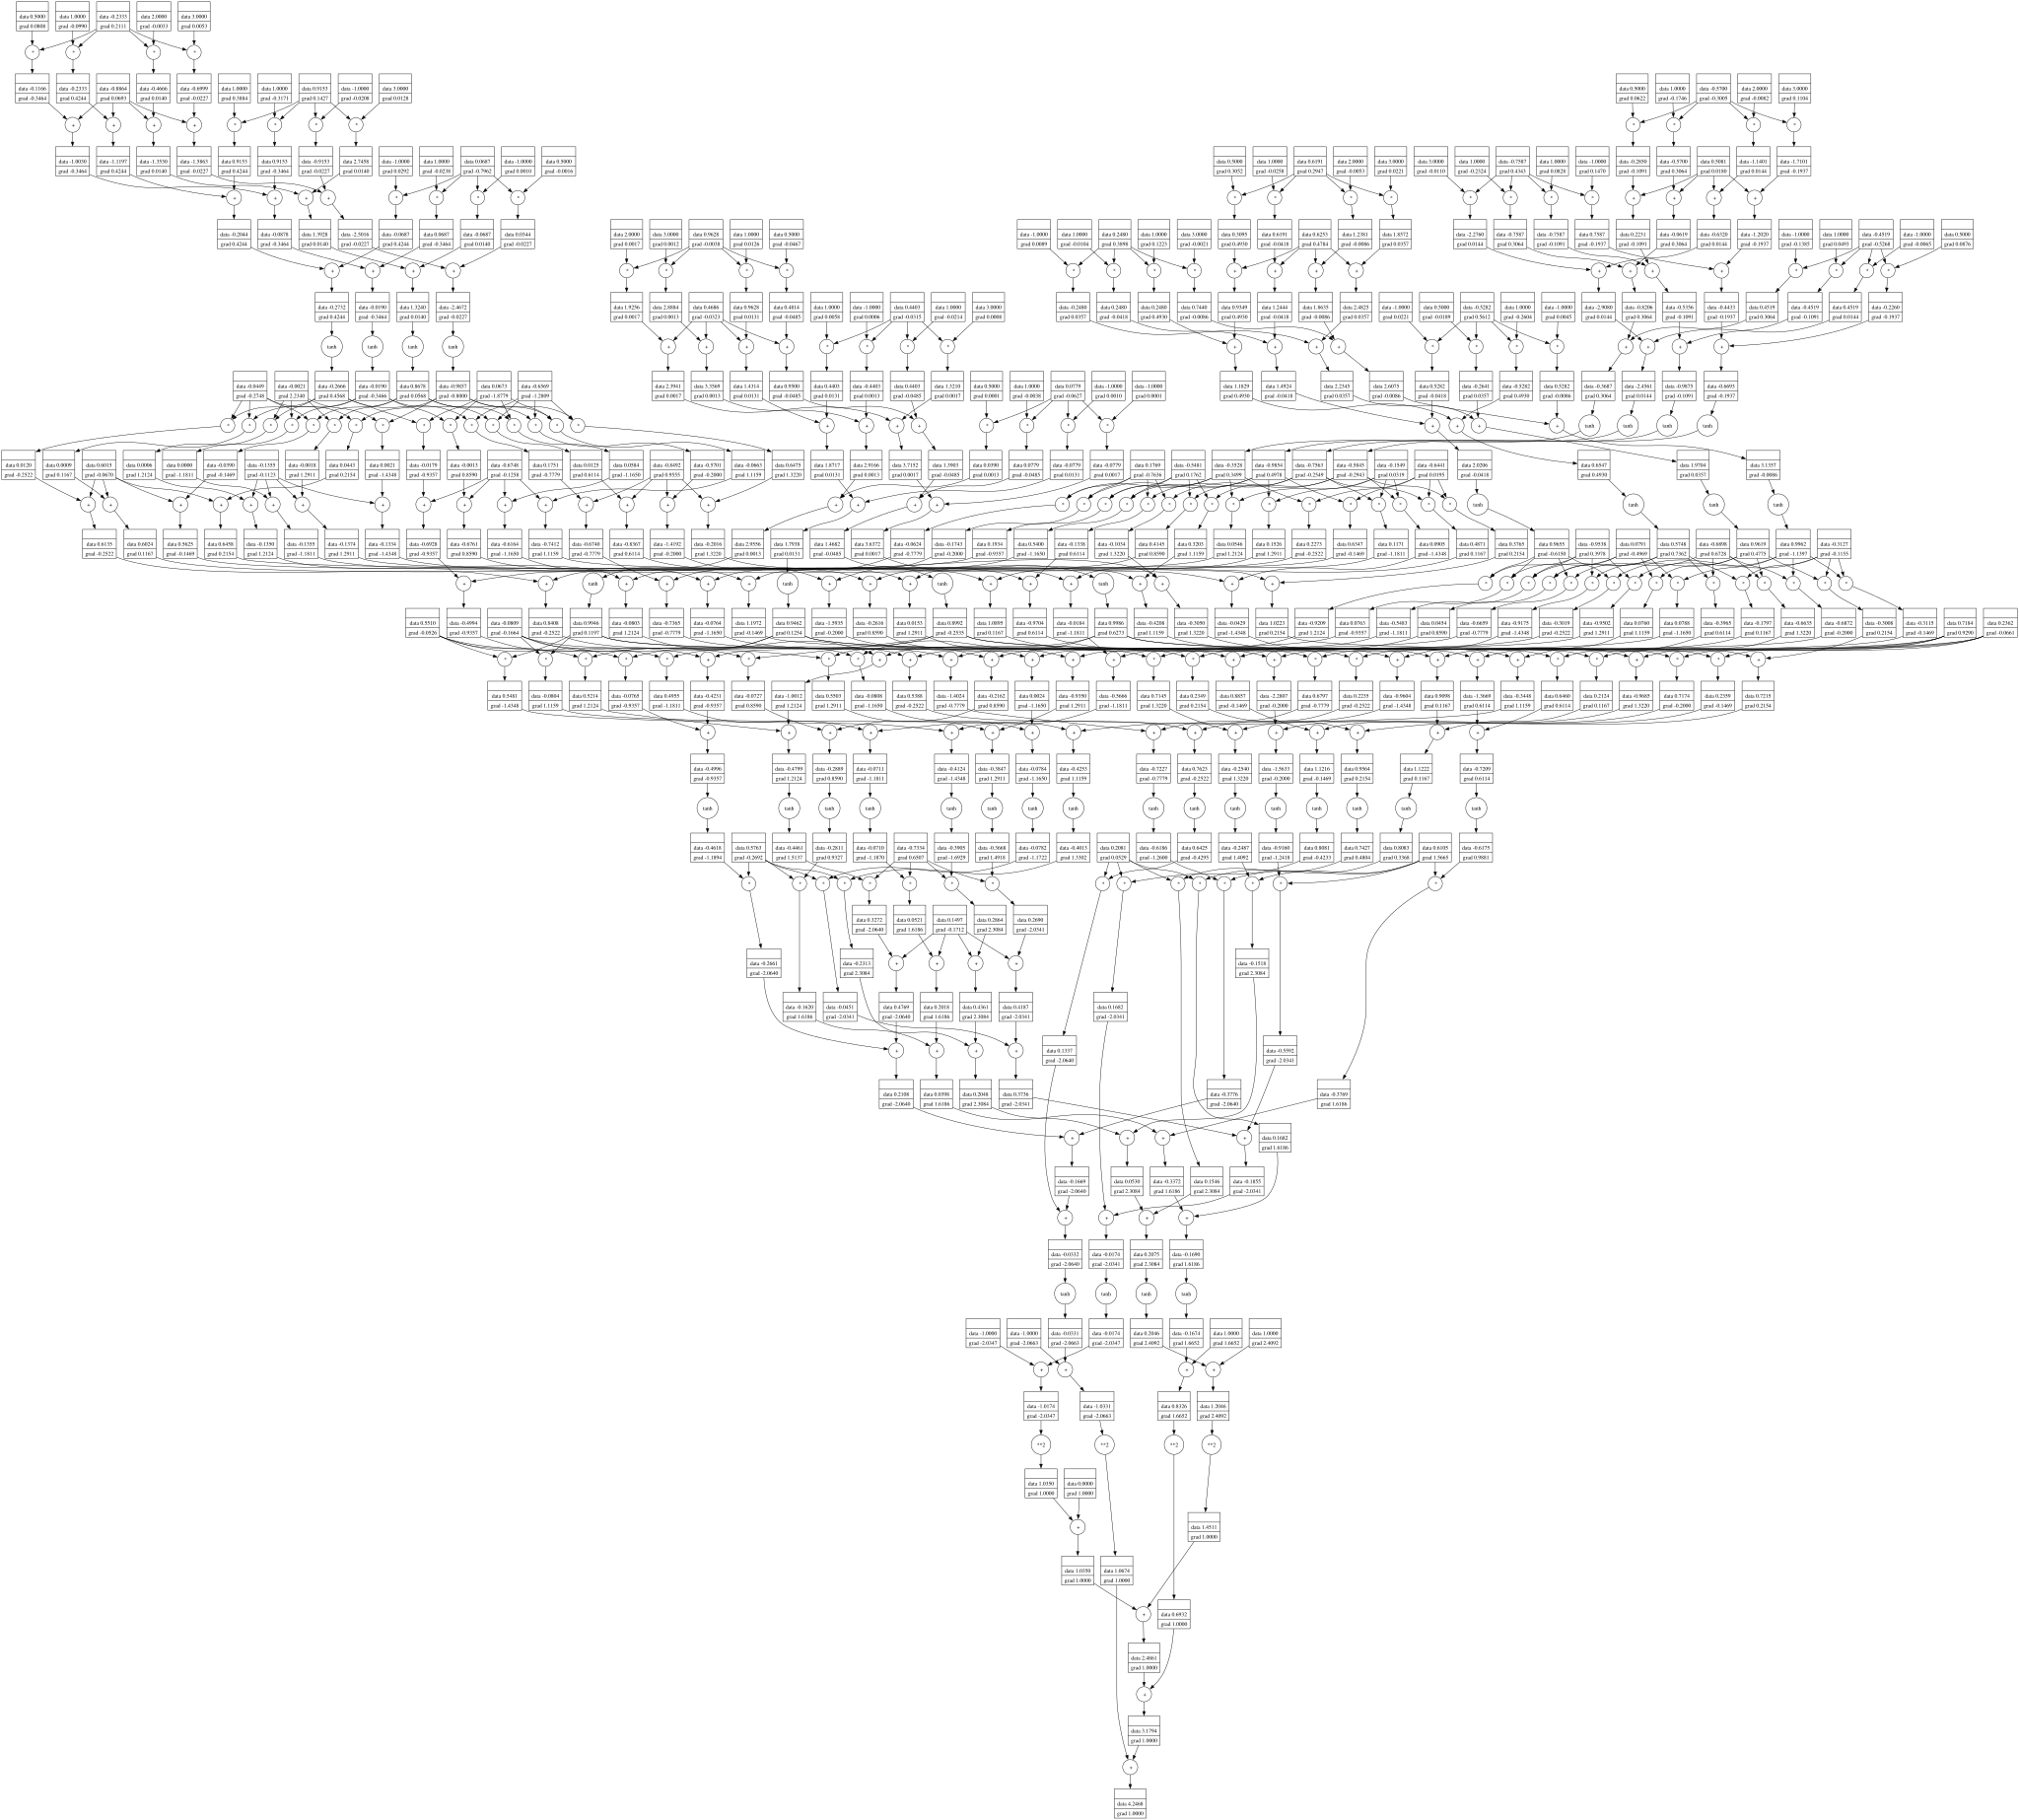

In [191]:
draw_dot(loss)

In [193]:
class Neuron:

    def __init__(self, nin): #nin is the number of inputs to the neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # weights of the neuron by randomly selecting the value between -1 and 1 
        self.b = Value(random.uniform(-1,1)) # bias of the neuron by randomly selecting the value between -1 and 1

    def __call__(self,x):
        # w * x +b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout): # nout is the number of outpouts 
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]



class MLP:
    def __init__(self, nin,nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x 

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


In [194]:
    
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=-0.14667869633632094)

In [195]:
n.parameters()

[Value(data=0.8806504800405461),
 Value(data=-0.7511011073870826),
 Value(data=-0.3945572946287528),
 Value(data=-0.12009112069959049),
 Value(data=0.8822338172342357),
 Value(data=-0.11352729442595133),
 Value(data=-0.6893451319219335),
 Value(data=-0.15201657491459675),
 Value(data=0.12811175850809065),
 Value(data=-0.2506220544534761),
 Value(data=-0.12410340315336033),
 Value(data=-0.6187462042338987),
 Value(data=0.29248639673417487),
 Value(data=-0.15771434419534391),
 Value(data=0.5486607499248917),
 Value(data=-0.397285709237867),
 Value(data=-0.4211697996642909),
 Value(data=-0.1724430955873557),
 Value(data=-0.2253512447132009),
 Value(data=0.5219707899620454),
 Value(data=-0.029534953596620284),
 Value(data=-0.4122525554461871),
 Value(data=0.9383073283274803),
 Value(data=-0.3488801273412754),
 Value(data=-0.5861707906588338),
 Value(data=0.25156847237462077),
 Value(data=0.8165425854299146),
 Value(data=-0.1648531982339707),
 Value(data=-0.027270357125685818),
 Value(data=

In [196]:
len(n.parameters())

41

In [197]:
xs = [  [2.0,3.0,-1.0],
        [3.0,-1.0,0.5],
        [0.5,1.0,1.0],
        [1.0,1.0,-1.0]]

ys = [1.0,-1.0,-1.0,1.0] # desired targets 

ypred = [n(x) for x in xs]
ypred

[Value(data=-0.14667869633632094),
 Value(data=-0.7854885642576066),
 Value(data=0.6954251037915579),
 Value(data=-0.7028843210947424)]

In [198]:
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))
loss

Value(data=7.135168482292745)

In [199]:
loss.backward()

In [200]:
n.layers[0].neurons[0].w[0].data

0.8806504800405461

In [201]:
n.layers[0].neurons[0].w[0].grad

7.789670176770992

In [203]:
for p in n.parameters():
    p.data += -0.01 * p.grad


In [204]:
n.layers[0].neurons[0].w[0].data

0.8027537782728362

In [205]:
ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=4.714052496133399)

In [ ]:
loss.backward()

In [209]:
for p in n.parameters():
    p.data += -0.01 * p.grad


In [210]:
ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=3.14063264092057)

In [211]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=2.7266302015608694)

In [212]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=1.785354979058828)

In [213]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.727979093504164)

In [214]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.5172428734528437)

In [215]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=1.4006828507124065)

In [216]:
ypred

[Value(data=-0.06888607334594296),
 Value(data=-0.7332352153141789),
 Value(data=-0.8794434150133394),
 Value(data=0.5847072449616059)]

In [217]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=1.941306891167349)

In [218]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=1.048990245672002)

In [219]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.46005028300961176)

In [220]:
ypred

[Value(data=0.5768425021044579),
 Value(data=-0.5157989640266984),
 Value(data=-0.9708320527331942),
 Value(data=0.786255754231796)]

In [221]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.6880901341708973)

In [222]:
ypred

[Value(data=0.7875820358648705),
 Value(data=-0.2086695387161644),
 Value(data=-0.9780841853949732),
 Value(data=0.8723891039209661)]

In [223]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.7792232184777549)

In [224]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.20454204074416485)

In [225]:
ypred

[Value(data=0.8893496237499394),
 Value(data=-0.5689914773519447),
 Value(data=-0.9888853155828619),
 Value(data=0.9199584347046293)]

In [226]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.019919677328449046)

In [227]:
ypred

[Value(data=0.9056861244730858),
 Value(data=-0.92480180867303),
 Value(data=-0.9922858719626154),
 Value(data=0.9271282327556273)]

In [228]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.011308547645134937)

In [229]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.009120681007041961)

In [230]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.007691580894400652)

In [231]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.006727864730404017)

In [232]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.006083605336119981)

In [233]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.005657619699761734)

In [234]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.005377194060953453)

In [235]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.005188026830015944)

In [236]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.005047655334775497)

In [237]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.004922100104038062)

In [238]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.004785281333222329)

In [239]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.004619930719092651)

In [240]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.004418211585523699)

In [241]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.004180821603698724)

In [242]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.003914582762350631)

In [243]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.003629430204074251)

In [244]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.0033358057997532877)

In [245]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=0.0030429734023630873)

In [246]:
ypred

[Value(data=0.9611128574849528),
 Value(data=-0.9996086330360225),
 Value(data=-0.9995073933349733),
 Value(data=0.960880085379048)]

In [309]:
loss.backward()

for p in n.parameters():
    p.data += -0.01 * p.grad


ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

loss

Value(data=8.882931296594731e-07)

In [310]:
ypred

[Value(data=0.9993447913905945),
 Value(data=-0.9999986573635485),
 Value(data=-0.9998276785461961),
 Value(data=0.9993447913906955)]

In [312]:
n.parameters()

[Value(data=-1.725236528572616),
 Value(data=-20.18701258692214),
 Value(data=16.84345542930248),
 Value(data=-4.907849135539345),
 Value(data=1.9846217583676053),
 Value(data=9.483486284991843),
 Value(data=-10.373956946666894),
 Value(data=-1.704701932534759),
 Value(data=-3.066409736249391),
 Value(data=7.488064678358614),
 Value(data=-4.038896137177091),
 Value(data=0.21962683925334142),
 Value(data=1.5943521845474429),
 Value(data=-2.151793142633947),
 Value(data=6.181389863613),
 Value(data=2.386014050295926),
 Value(data=0.9926585672401333),
 Value(data=6.235486232025026),
 Value(data=-0.2593901823909462),
 Value(data=-4.461546496854017),
 Value(data=0.4388379929348657),
 Value(data=-9.668182288508701),
 Value(data=5.149470841982327),
 Value(data=6.572527999858547),
 Value(data=-5.302982650121226),
 Value(data=-7.0898986482831905),
 Value(data=0.33286308993709185),
 Value(data=-7.545968933665989),
 Value(data=3.011872954759281),
 Value(data=7.420133894890367),
 Value(data=-3.420

In [320]:
class Neuron:

    def __init__(self, nin): #nin is the number of inputs to the neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # weights of the neuron by randomly selecting the value between -1 and 1 
        self.b = Value(random.uniform(-1,1)) # bias of the neuron by randomly selecting the value between -1 and 1

    def __call__(self,x):
        # w * x +b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout): # nout is the number of outpouts 
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]



class MLP:
    def __init__(self, nin,nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x 

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


In [321]:
    
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.4281069390287451)

In [322]:
xs = [  [2.0,3.0,-1.0],
        [3.0,-1.0,0.5],
        [0.5,1.0,1.0],
        [1.0,1.0,-1.0]]

ys = [1.0,-1.0,-1.0,1.0] # desired targets 

ypred = [n(x) for x in xs]
ypred

[Value(data=0.4281069390287451),
 Value(data=0.4946340923336312),
 Value(data=0.38054844844347674),
 Value(data=0.5225981754227951)]

In [579]:
for k in range(30):
    
    #forward pass
    ypred = [n(x) for x in xs]
    loss = sum(((yout - ygt)**2 for ygt,yout in zip(ys,ypred)),Value(0.0))

    #backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update ( gradient descent)
    for p in n.parameters():
        p.data += -0.01 * p.grad

    print(k,loss.data)


0 0.00031188775456377946
1 0.00031184380560896486
2 0.0003117998688810289
3 0.0003117559443749101
4 0.00031171203208552083
5 0.00031166813200781275
6 0.0003116242441367053
7 0.0003115803684671435
8 0.0003115365049940783
9 0.00031149265371243864
10 0.00031144881461718087
11 0.00031140498770325294
12 0.0003113611729656085
13 0.00031131737039919604
14 0.0003112735799989846
15 0.00031122980175992554
16 0.00031118603567698965
17 0.0003111422817451366
18 0.00031109853995934356
19 0.00031105481031458004
20 0.0003110110928058136
21 0.00031096738742802975
22 0.00031092369417620665
23 0.0003108800130453241
24 0.0003108363440303707
25 0.0003107926871263402
26 0.00031074904232821605
27 0.0003107054096309934
28 0.00031066178902966924
29 0.0003106181805192503


In [580]:
ypred

[Value(data=0.9950251870696103),
 Value(data=-0.988462353835821),
 Value(data=-0.9924141074727113),
 Value(data=0.990242624718629)]